# 07 — Final Mid-Course DNN: Train, Save, and Verify

**Goal:** Create one deployable DNN for predicting `G3` performance category **after G1 and G2 are available**. This notebook preserves the existing early-prediction model.

**Data integrity:** Reproduce the original 519-student development partition and 130-student previously examined test partition. Train on **415 students**, use **104 students** for Early Stopping and descriptive validation, and **do not evaluate or tune on the 130-student test partition**. The validation partition has already informed previous experimentation; its metrics are *not* a fresh independent performance estimate. The five-fold cross-validation results in notebook 06 provide the more useful development-data comparison.

**Deployment artifacts:** `models/midcourse_dnn.keras`, `models/midcourse_preprocessor.pkl`, `models/midcourse_label_encoder.pkl`, `models/midcourse_metadata.json`.

**Run from:** the repository's `notebooks/` directory. Notebook cells run in order.

## 1. Imports and reproducibility

In [1]:
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, ConfusionMatrixDisplay
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
tf.keras.utils.set_random_seed(SEED)
DATA_PATH = Path('../data/student-por.csv')
MODEL_DIR = Path('../models')
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print('TensorFlow version:', tf.__version__)
print('Model directory:', MODEL_DIR.resolve())

TensorFlow version: 2.21.0
Model directory: C:\Users\Hp\OneDrive\Desktop\student-performance-prediction\models


## 2. Dataset and target

Same thresholds as previous notebooks: **Low = G3 0–9**, **Average = 10–13**, **Good = 14–20**. `G3` is a label source only; it must not be a feature.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Missing dataset: {DATA_PATH.resolve()}. Open the notebook from notebooks/.')
df = pd.read_csv(DATA_PATH, sep=';')

def categorize_performance(g3):
    if g3 <= 9:
        return 'Low'
    if g3 <= 13:
        return 'Average'
    return 'Good'

df['performance_category'] = df['G3'].apply(categorize_performance)
X = df.drop(columns=['G3', 'performance_category'])
y = df['performance_category']
assert X.shape == (649, 32), f'Unexpected dataset/features: {X.shape}'
assert {'G1', 'G2'}.issubset(X.columns) and 'G3' not in X.columns
assert not X.isna().any().any(), 'Handle missing input values before training'
print('Features:', X.shape, '| Target:', y.shape)
print('Class counts:', y.value_counts())

Features: (649, 32) | Target: (649,)
Class counts: performance_category
Average    355
Good       194
Low        100
Name: count, dtype: int64


## 3. Reproduce the original split

We do not use the old test records. Keeping the same split makes the saved model consistent with the previously explored mid-course setup.

In [3]:
X_dev, X_test_unused, y_dev, y_test_unused = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.2, random_state=SEED, stratify=y_dev
)
assert (len(X_train), len(X_val), len(X_test_unused)) == (415, 104, 130)
print(f'Train: {len(X_train)}, Validation: {len(X_val)}, Test excluded: {len(X_test_unused)}')

Train: 415, Validation: 104, Test excluded: 130


## 4. Fit preprocessing on training rows only

The preprocessor must be saved alongside the model: the neural network cannot directly process raw categorical values.

In [4]:
feature_columns = X_train.columns.tolist()
numeric_features = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])
X_train_processed = np.asarray(preprocessor.fit_transform(X_train), dtype=np.float32)
X_val_processed = np.asarray(preprocessor.transform(X_val), dtype=np.float32)
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_encoded), y=y_train_encoded)
class_weights = {int(k): float(v) for k, v in zip(np.unique(y_train_encoded), weights)}
print('Raw features:', len(feature_columns), '| Processed features:', X_train_processed.shape[1])
print('Label mapping:', dict(enumerate(label_encoder.classes_)))
print('Class weights:', class_weights)
assert X_train_processed.shape[1] == X_val_processed.shape[1]
assert np.isfinite(X_train_processed).all() and np.isfinite(X_val_processed).all()

Raw features: 32 | Processed features: 58
Label mapping: {0: 'Average', 1: 'Good', 2: 'Low'}
Class weights: {0: 0.6093979441997063, 1: 1.1155913978494623, 2: 2.1614583333333335}


## 5. Build the selected DNN

Use the fixed architecture and training settings from notebooks 05 and 06; this is not another hyperparameter search.

In [5]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(len(label_encoder.classes_), activation='softmax')
])
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,955 (23.26 KB)

 Trainable params: 5,955 (23.26 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train with Early Stopping

The restored weights correspond to the minimum validation loss, **not necessarily** the highest validation accuracy.

In [6]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = model.fit(
    X_train_processed, y_train_encoded,
    validation_data=(X_val_processed, y_val_encoded),
    epochs=100, batch_size=32, class_weight=class_weights,
    callbacks=[early_stopping], verbose=1
)
best_epoch = int(np.argmin(history.history['val_loss']) + 1)
print('Epochs trained:', len(history.history['loss']))
print('Best epoch (validation loss):', best_epoch)
print('Minimum validation loss:', round(float(min(history.history['val_loss'])), 4))

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.3614 - loss: 1.1173 - val_accuracy: 0.5096 - val_loss: 1.0015
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4337 - loss: 0.9658 - val_accuracy: 0.5577 - val_loss: 0.9401
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4723 - loss: 0.8946 - val_accuracy: 0.5865 - val_loss: 0.8902
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5277 - loss: 0.7894 - val_accuracy: 0.6058 - val_loss: 0.8421
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5494 - loss: 0.7372 - val_accuracy: 0.6442 - val_loss: 0.7909
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6096 - loss: 0.6859 - val_accuracy: 0.6346 - val_loss: 0.7449
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6072 - loss: 0.6462 - val_accuracy: 0.6731 - val_loss: 0.7003
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6723 - loss: 0.5723 - val_accuracy: 0.

## 7. Learning curves

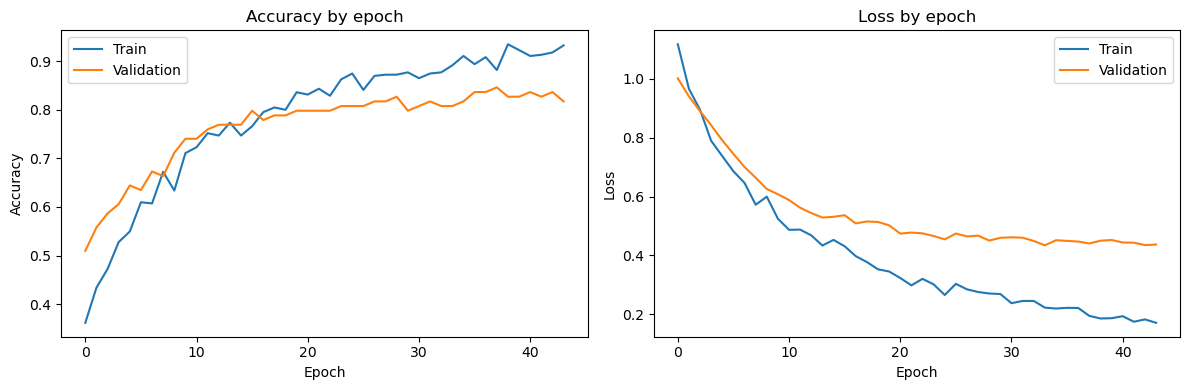

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, label in zip(axes, ['accuracy', 'loss'], ['Accuracy', 'Loss']):
    ax.plot(history.history[key], label='Train')
    ax.plot(history.history['val_' + key], label='Validation')
    ax.set(xlabel='Epoch', ylabel=label, title=f'{label} by epoch')
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Descriptive validation check

These 104 records were used for Early Stopping and earlier experiments. This is a **sanity check**, not an unbiased test estimate. The Low recall matters because missing at-risk students is consequential.

accuracy: 80.77%
macro_f1: 77.22%
low_recall: 62.50%
Classification report:
              precision    recall  f1-score   support

     Average       0.85      0.79      0.82        57
        Good       0.85      0.94      0.89        31
         Low       0.59      0.62      0.61        16

    accuracy                           0.81       104
   macro avg       0.76      0.78      0.77       104
weighted avg       0.81      0.81      0.81       104



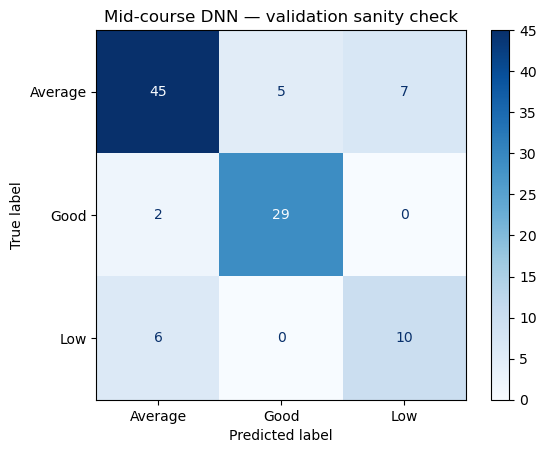

In [8]:
val_probs = model.predict(X_val_processed, verbose=0)
val_pred = np.argmax(val_probs, axis=1)
low_id = int(label_encoder.transform(['Low'])[0])
validation_metrics = {
    'accuracy': float(accuracy_score(y_val_encoded, val_pred)),
    'macro_f1': float(f1_score(y_val_encoded, val_pred, average='macro', zero_division=0)),
    'low_recall': float(recall_score(y_val_encoded, val_pred, labels=[low_id], average='macro', zero_division=0))
}
for key, value in validation_metrics.items():
    print(f'{key}: {value:.2%}')
print('Classification report:')
print(classification_report(y_val_encoded, val_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_val_encoded, val_pred,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_, cmap='Blues', values_format='d')
plt.title('Mid-course DNN — validation sanity check')
plt.show()

## 9. Save all deployment artifacts

Save **four files together**. Metadata includes feature order and categorical options to support safe Streamlit inputs. Do not overwrite the original `final_dnn.keras` or `dnn_preprocessor.pkl`.

In [9]:
model_path = MODEL_DIR / 'midcourse_dnn.keras'
preprocessor_path = MODEL_DIR / 'midcourse_preprocessor.pkl'
encoder_path = MODEL_DIR / 'midcourse_label_encoder.pkl'
metadata_path = MODEL_DIR / 'midcourse_metadata.json'

model.save(model_path)
joblib.dump(preprocessor, preprocessor_path)
joblib.dump(label_encoder, encoder_path)

category_options = {
    col: [str(v) for v in sorted(X_train[col].dropna().unique())]
    for col in categorical_features
}
metadata = {
    'model_type': 'DNN mid-course G3 performance category',
    'prediction_timing': 'after G1 and G2 are available',
    'training_rows': len(X_train),
    'early_stopping_validation_rows': len(X_val),
    'test_rows_not_used': len(X_test_unused),
    'seed': SEED,
    'raw_feature_columns': feature_columns,
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'categorical_options_from_training': category_options,
    'processed_input_dimension': int(X_train_processed.shape[1]),
    'classes_in_probability_order': label_encoder.classes_.tolist(),
    'grade_thresholds': {'Low': '0-9', 'Average': '10-13', 'Good': '14-20'},
    'best_epoch_by_validation_loss': best_epoch,
    'validation_metrics_descriptive_only': validation_metrics,
    'independent_test_evaluation': 'not performed for this model'
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
for p in (model_path, preprocessor_path, encoder_path, metadata_path):
    print(f'Saved: {p.resolve()} ({p.stat().st_size:,} bytes)')

Saved: C:\Users\Hp\OneDrive\Desktop\student-performance-prediction\models\midcourse_dnn.keras (101,437 bytes)
Saved: C:\Users\Hp\OneDrive\Desktop\student-performance-prediction\models\midcourse_preprocessor.pkl (7,020 bytes)
Saved: C:\Users\Hp\OneDrive\Desktop\student-performance-prediction\models\midcourse_label_encoder.pkl (496 bytes)
Saved: C:\Users\Hp\OneDrive\Desktop\student-performance-prediction\models\midcourse_metadata.json (2,860 bytes)


## 10. Reload artifacts and verify identical predictions

The important deployment test: does the model still work after loading it from disk? Compare probabilities before/after saving on validation rows; this is an **artifact consistency check**, not a new evaluation.

In [10]:
loaded_model = tf.keras.models.load_model(model_path)
loaded_preprocessor = joblib.load(preprocessor_path)
loaded_encoder = joblib.load(encoder_path)
loaded_metadata = json.loads(metadata_path.read_text(encoding='utf-8'))

assert loaded_metadata['raw_feature_columns'] == feature_columns
assert loaded_metadata['classes_in_probability_order'] == loaded_encoder.classes_.tolist()
assert loaded_model.input_shape[-1] == loaded_metadata['processed_input_dimension']

reloaded_input = np.asarray(
    loaded_preprocessor.transform(X_val[feature_columns]), dtype=np.float32
)
reloaded_probs = loaded_model.predict(reloaded_input, verbose=0)
np.testing.assert_allclose(val_probs, reloaded_probs, rtol=1e-5, atol=1e-6)
assert np.allclose(reloaded_probs.sum(axis=1), 1, atol=1e-5)
print('PASS: Reloaded model produces matching validation probabilities.')
print('Input shape:', loaded_model.input_shape)
print('Output classes:', loaded_encoder.classes_.tolist())

PASS: Reloaded model produces matching validation probabilities.
Input shape: (None, 58)
Output classes: ['Average', 'Good', 'Low']


## 11. One example of Streamlit-ready inference

Pass a **DataFrame with all 32 original columns in saved order**. Here we use a known validation row solely to verify the interface; this is not a real user prediction.

In [11]:
def predict_midcourse(student_row: dict):
    required = loaded_metadata['raw_feature_columns']
    missing = [name for name in required if name not in student_row]
    if missing:
        raise ValueError(f'Missing required fields: {missing}')
    if student_row['G1'] is None or student_row['G2'] is None:
        raise ValueError('G1 and G2 must be available for mid-course prediction.')
    row = pd.DataFrame([{name: student_row[name] for name in required}], columns=required)
    transformed = np.asarray(loaded_preprocessor.transform(row), dtype=np.float32)
    probabilities = loaded_model.predict(transformed, verbose=0)[0]
    return {
        'predicted_category': str(loaded_encoder.inverse_transform([int(np.argmax(probabilities))])[0]),
        'probabilities': {str(cls): float(p) for cls, p in zip(loaded_encoder.classes_, probabilities)}
    }

example = predict_midcourse(X_val.iloc[0].to_dict())
print('Example output (not a performance claim):')
print(json.dumps(example, indent=2))

Example output (not a performance claim):
{
  "predicted_category": "Average",
  "probabilities": {
    "Average": 0.8161017894744873,
    "Good": 0.17995814979076385,
    "Low": 0.003940103575587273
  }
}
